# GPT to Llama2

nanoGPT 基于 GPT2 和 GPT3 的论文实现了 GPT 模型的核心架构。相对而言，GPT 模型在 Transformer 架构的基础上没有做太多的改变，所做的改变具体如下：
- 用 pre-norm 取代 post-norm 进行层归一化
- 用 GELU 取代 ReLU 作为激活函数
- 在最后的投影层之前，添加一层 layernorm
- token embedding 和最后的线性层共享权重
- 用 FlashAttention 对 传统多头因果自注意力 进行加速（没有改变架构）

而 Llama2 和 Llama3 在此基础上又进行了一些改动。这个 notebook 将主要跟随 `github rasbt/LLMs-from-scratch/ch05/07_gpt_to_llama` 的内容，在 GPT 的基础上，将 GPT 改为 Llama3，并讲解这些改动。

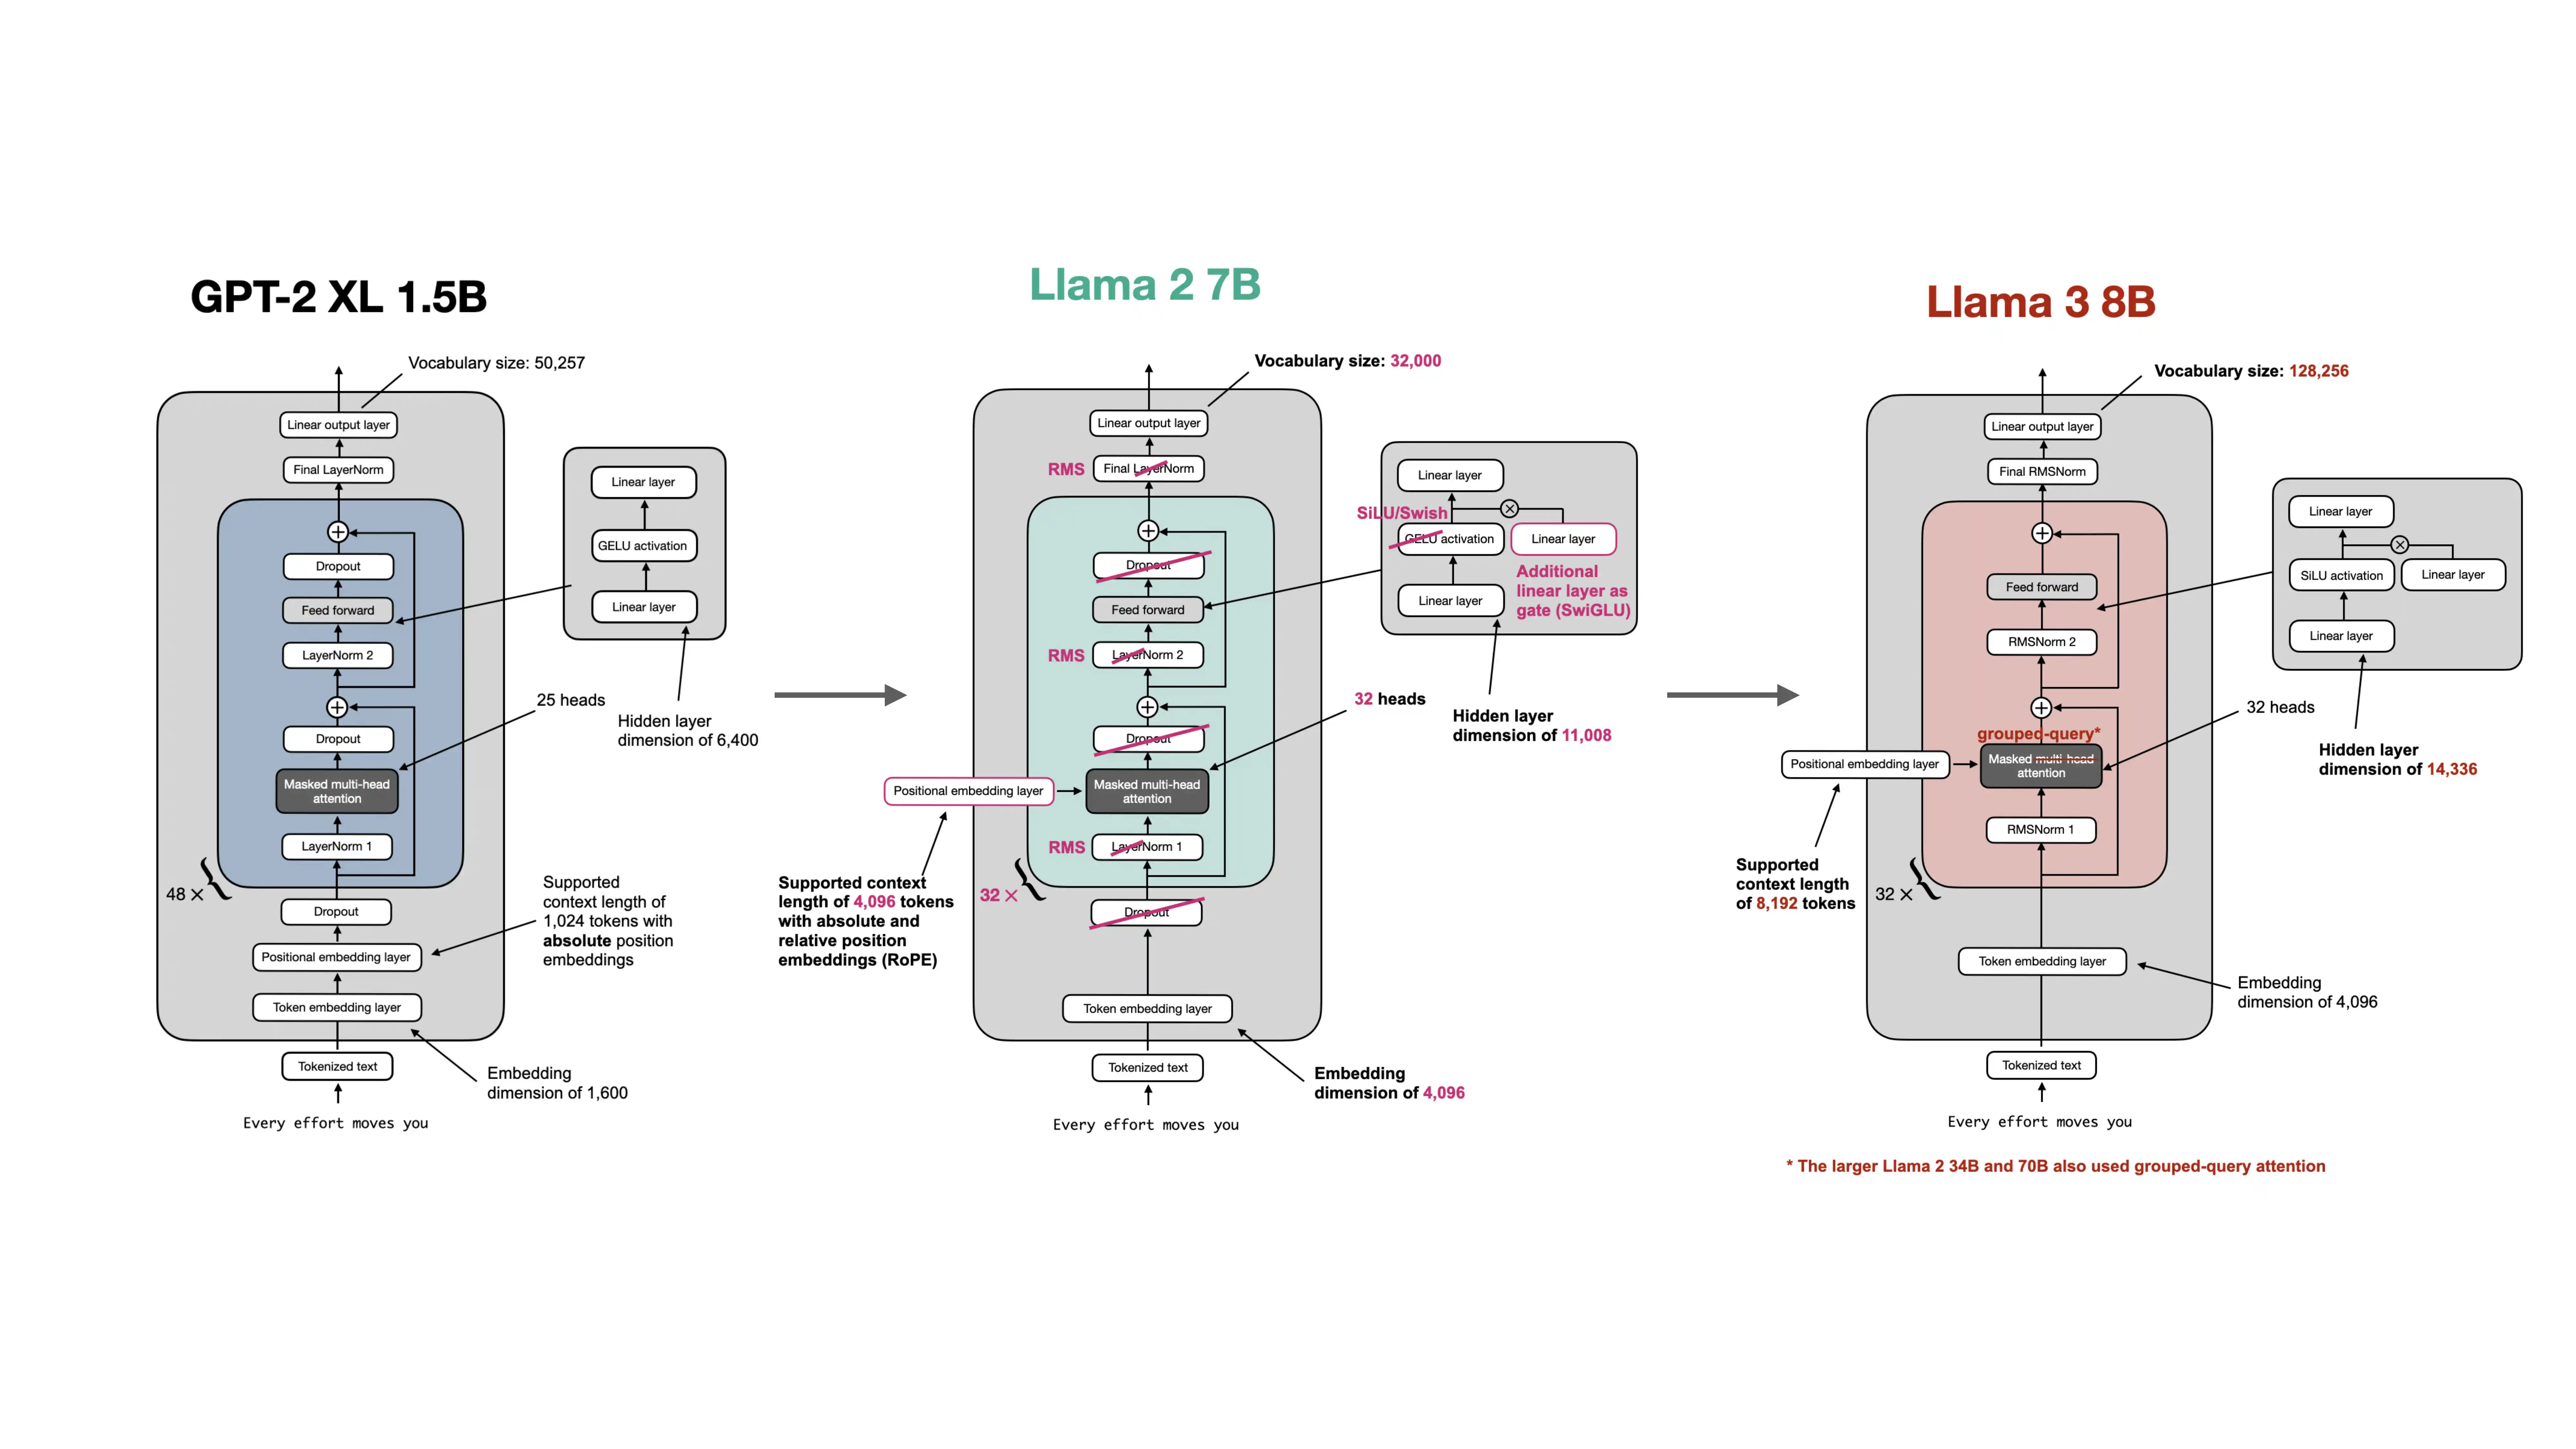

Llama1 和 Llama2 的架构基本上相同，但 Llama2 有更长的上下文窗口且更少的使用限制，而且能够获取到模型权重，所以第一步我们把 GPT 更新成 Llama2 开始。分两步进行主要为了体现 Llama 模型内部的迭代过程。

In [6]:
import torch
import torch.nn as nn

## GPT to Llama2

### RMSNorm

在同名论文中，作者通过研究发现 LayerNorm **真正起作用的是“重新缩放”**（re-scaling）即均方根归一化，减均值的操作并没有带来关键收益，即“重新中心化”（re-centering）是不必要的。因此提出了 RMSNorm。作者在多个任务和架构上经过实验发现，RMSNorm 更便宜、更稳、效果通常不差甚至更好。

公式对比：

- LayerNorm：  
  $$
  y=\gamma \odot \frac{x-\mu}{\sqrt{\sigma^2+\epsilon}}+\beta
  $$
  要算均值 $\mu$ 和方差 $\sigma^2$，还有偏置 $\beta$。

- RMSNorm：  
  $$
  y=\gamma \odot \frac{x}{\sqrt{\frac{1}{d}\sum_i x_i^2+\epsilon}}
  $$
  只算均方根，不减均值，通常也没有偏置 $\beta$。

RMSNorm 有突出的优势，在 2024 年被 Llama 直接团队采用。在 2026 这个时间点，主流的大语言模型如 deepseek41、Qwen35、GLM5 依然使用 RMSNorm 的定制化改良版本。

1. **计算更省**
   RMSNorm 省掉了求均值、减均值、以及 bias 加法。

2. **分布式训练通信更友好**
   在张量并行等切分方式下，LayerNorm 沿隐藏维归一化时通常要同步均值和方差两个统计量；RMSNorm 只需要同步均方根一个统计量。

3. **参数和优化器状态更少**
   RMSNorm 没有 bias，只保留一个缩放向量 $\gamma$。

4. **和 Pre-Norm 架构很搭**
   Pre-Norm 本身训练更稳定，对归一化的中心化需求降低。RMSNorm 放在子层前，只缩放不中心化，残差路径更简单，也更适合深层 Transformer。

5. **硬件和工程实现友好**
   RMSNorm 更容易和 residual add 融合成 fused kernel，比如 `fused_add_rmsnorm`，减少显存往返。

In [7]:
# class LayerNorm(nn.Module):
#     def __init__(self, emb_dim):
#         super().__init__()
#         self.eps = 1e-5
#         self.scale = nn.Parameter(torch.ones(emb_dim))
#         self.shift = nn.Parameter(torch.zeros(emb_dim))

#     def forward(self, x):
#         mean = x.mean(dim=-1, keepdim=True)
#         var = x.var(dim=-1, keepdim=True, unbiased=False)
#         norm_x = (x - mean) / torch.sqrt(var + self.eps)
#         return self.scale * norm_x + self.shift


class RMSNorm(nn.Module):
    def __init__(self, emb_dim, eps=1e-5):
        super().__init__()
        self.eps = eps
        self.emb_dim = emb_dim
        self.weight = nn.Parameter(torch.ones(emb_dim)).float()

    def forward(self, x):
        means = x.pow(2).mean(dim=-1, keepdim=True)
        x_normed = x * torch.rsqrt(means + self.eps)
        return (x_normed * self.weight).to(dtype=x.dtype)

GPT 中有三处使用了 nn 的 LayerNorm，直接改成 RMSNorm 就可以。我们在最后的 Llama2Model 中修改。

### SiLU 激活函数

用 SiLU 取代 GELU 主要是因为，当它用于门控 FFN（SwiGLU）时，在大规模 Transformer 上表现通常更好。实际上两个函数图像十分接近，单独使用时差距不大，SiLU 计算量小一些。**真正的收益来自于下一节的 SwiGLU 门控结构**。

两者定义：

$$
\text{GELU}(x)=x\Phi(x)
$$

$$
\text{SiLU}(x)=x\sigma(x)=\frac{x}{1+e^{-x}}
$$

其中 $\Phi$ 是正态分布 CDF，$\sigma$ 是 sigmoid。GELU 常近似为：

$$
\text{GELU}(x)\approx x\sigma(1.702x)
$$

所以 **SiLU 可以看作 GELU 的一个更简单、logistic 版本的近似**。

In [8]:
# class GELU(nn.Module):
#     def __init__(self):
#         super().__init__()

#     def forward(self, x):
#         return 0.5 * x * (1 + torch.tanh(
#             torch.sqrt(torch.tensor(2.0 / torch.pi)) *
#             (x + 0.044715 * torch.pow(x, 3))
#         ))


class SiLU(nn.Module):
    def __init__(self):
        super(SiLU, self).__init__()

    def forward(self, x):
        return x * torch.sigmoid(x)

只用在 FFN 中，Transformer 架构才使用激活函数，所以和下面的 SwiGLU 一并修改。

### SwiGLU 的 FeedForward

实际上是一种 “Gates Linear Unit(GLU)” ，即门控的前递（全连接）层。SwiGLU 使用 SiLU 作为门控单元的激活函数。

$$\text{SwiGLU}(x) = \text{SiLU}(\text{Linear}_1(x)) * (\text{Linear}_2(x))$$

门控过后还需要经过一个线性层。整个 FFN 层的输出公式为：

$$\text{FFN}(x)=(\text{SiLU}(xW_g)\odot xW_u)W_d$$

即一个门控的 FFN 层。

In [9]:
# 用于 FFN 的全连接层
# class MLP(nn.Module):
    
#     def __init__(self, config):
#         super().__init__()
#         self.c_fc = nn.Linear(config.n_embd, 4 * config.n_embd)
#         self.gelu = nn.GELU(approximate='tanh') # 使用 GELU（优化 ReLU）的 tanh 近似
#         # GPT2 使用了 tanh 近似，理由是运算更快。实际上现在已经直接使用 GELU 的为多数。
#         self.c_proj = nn.Linear(4 * config.n_embd, config.n_embd)
#         # MLP 输出后就是 res，所以需要使用 scale 初始化
#         self.c_proj.NANOGPT_SCALE_INIT = 1
    
#     def forward(self, x):
#         x = self.c_proj(self.gelu(self.c_fc(x)))
#         return x

另外 Llama 更改后的 FFN 的隐藏层不严格满足四倍关系。主要原因是**要保证和传统 FFN 计算量一致**。SwiGLU 比传统 FFN 多了一个线性层，所以隐藏层的大小大致需要选择为： $$ \frac{8}{3} \times dim_{embed} $$

In [ ]:
class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.fc1 = nn.Linear(cfg["emb_dim"], cfg["hidden_dim"], dtype=cfg["dtype"], bias=False) # gate
        self.fc2 = nn.Linear(cfg["emb_dim"], cfg["hidden_dim"], dtype=cfg["dtype"], bias=False) # up
        self.fc3 = nn.Linear(cfg["hidden_dim"], cfg["emb_dim"], dtype=cfg["dtype"], bias=False) # down
        self.silu = SiLU()
    
    def forward(self, x):
        x_fc1 = self.fc1(x)
        x_fc2 = self.fc2(x)
        x = self.silu(x_fc1) * x_fc2
        return self.fc3(x)

### RoPE 位置编码

传统 PE 位置编码有两种，都存在自己的问题：

- 正余弦绝对编码：能很好表征相对位置，但在注意力层的 $ Q \times K^T $ 操作中，会引入无意义的噪声项。
- 可学习绝对编码：长上下文窗口时参数量爆炸。外推性能差。

后续发展出的可学习的相对位置编码，部分解决了外推问题，但通常需要改 attention 结构或者增加参数数量，很可能还不支持 Flash Attention，无法根本地解决问题。

Rotary Position Embedding 即旋转位置编码，**通过旋转矩阵巧妙地解决了正余弦绝对编码的噪声项问题**，带来了更好地外推性能，不影响高效注意力，且简单、符合直觉而实验有效，在 2026 年仍是主流大模型的选择。

#### 正余弦绝对编码的问题

正余弦绝对编码自身的“位置-位置”内积确实只依赖相对距离；但注意力算的是 $QK^T$，而 Q或K 通常是“内容 + 位置”，展开后会出现内容与位置的交叉项，这些项不是相对位置的函数，因此像是无意义的噪声或干扰，模型需要通过大量的优化或参数去学习纯净的位置信息。

下面从不考虑线性投影层进行简单推导。

设 token 内容向量为 $x_i$，正余弦位置编码为 $p_i$。忽略线性投影：

$$
q_i = x_i + p_i,\qquad k_j = x_j + p_j
$$

注意力分数为：

$$
s_{ij}=q_i^T k_j=(x_i+p_i)^T(x_j+p_j)
$$

展开：

$$
s_{ij}=
\underbrace{x_i^T x_j}_{\text{内容-内容}}
+\underbrace{x_i^T p_j}_{\text{内容-位置}}
+\underbrace{p_i^T x_j}_{\text{位置-内容}}
+\underbrace{p_i^T p_j}_{\text{位置-位置}}
$$

这四项里，只有最后一项是真正干净的位置项。考虑线性投影后，问题会更严重。传统绝对位置编码在注意力层里，**位置信息被加性注入到内容中**，再经过投影和点积，导致内容-位置交叉项，以及被投影矩阵扭曲的位置-位置项。

#### RoPE 位置编码

传统 PE 是把位置“加”到 token 表示上的绝对坐标；RoPE 是**把位置“乘”到 Q/K 上做旋转**，让注意力点积只依赖相对距离。下面是 RoPE 数学上的定义。

把 d 维向量分成 d/2 个二维子空间（即两个维度为一组），每个子空间用不同频率旋转（通过两个维度为一组，保留使用二维旋转矩阵。再参考正余弦位置编码的核心——频率差异，让不同的组有不同的旋转速度）。定义：

$$
\theta_i = 10000^{-2i/d},\quad i=0,\dots,d/2-1
$$

这里 10000 是可以调的超参数，定义为 `theta_base` 。

位置 m 的旋转矩阵为：

$$
R_{m,i}=
\begin{pmatrix}
\cos m\theta_i & -\sin m\theta_i\\
\sin m\theta_i & \cos m\theta_i
\end{pmatrix}
$$

对 Q/K 做：

$$
q_m = R_m W_q x_m,\quad k_n = R_n W_k x_n
$$

因为旋转矩阵满足转置等价于顺时针旋转：

$$
R_m^T R_n = R_{n-m}
$$

于是注意力分数：

$$
q_m^T k_n
= (W_q x_m)^T R_m^T R_n (W_k x_n)
= (W_q x_m)^T R_{n-m} (W_k x_n)
$$

所以内积只依赖相对位置 $n-m$。用复数看更直观：把每个二维子空间看成复数，位置 m 相当于乘以 $e^{im\theta}$，两个位置的内积自然只留下 $e^{i(n-m)\theta}$ 。

#### RoPE 代码实现

#（*请忽略这个# 仅用于保持 VSCode 中大纲不被 bug 影响*）
下面的 RoPE 实现中，为了实现的方便把 $(x_i, x_{i+d/2})$ 配成一对，而原始 RoPE 论文常和上面的数学定义一样把 $(x_{2i}, x_{2i+1})$ 配成一对。LLaMA、Hugging Face 等常用这种方法实现，在模型中效果是完全等价的。
$$ 
\begin{bmatrix}
\cos\theta & -\sin\theta \\
\sin\theta & \cos\theta
\end{bmatrix}
\begin{bmatrix}
x_i \\
x_{i+d/2}
\end{bmatrix}
=
\begin{bmatrix}
x_i\cos\theta - x_{i+d/2}\sin\theta \\
x_i\sin\theta + x_{i+d/2}\cos\theta
\end{bmatrix} $$
即：

$$
\begin{aligned}
x_i' &= x_i\cos\theta_i - x_{i+d/2}\sin\theta_i \\
x_{i+d/2}' &= x_i\sin\theta_i + x_{i+d/2}\cos\theta_i
\end{aligned}
$$

下面通过两个函数实现上述运算。下一节会把这两个函数改写成类，代码几乎完全一致。

In [11]:
"""计算旋转矩阵所需要的 cos sin 数值"""
def precompute_rope_params(head_dim, theta_base=10_000, context_length=4096):
    assert head_dim % 2 == 0, "Embedding dimension must be even"
    # 确定所有的旋转速度 theta_i，生成一个 list，长度为 head_dim // 2
    inv_freq = 1.0 / (theta_base ** (torch.arange(0, head_dim, 2).float() / head_dim))
    # 生成所有位置索引
    positions = torch.arange(context_length)
    # 计算所有角度，用广播机制
    angles = positions.unsqueeze(1) * inv_freq.unsqueeze(0) # (context_length, head_dim // 2)
    # 扩展到 head_dim 维度，直接复制一份并 concat
    angles = torch.concat([angles, angles], dim=1)
    # 计算 sin 和 cos
    cos = torch.cos(angles)
    sin = torch.sin(angles)
    return cos, sin

# 对输入张量进行旋转编码
def compute_rope(x, cos, sin):
    # x: (batch_size, num_heads, seq_len, head_dim)
    batch_size, num_heads, seq_len, head_dim = x.shape
    assert head_dim % 2 == 0, "Head dimension must be even"
    
    # 将 x 的最后一维对半切分
    x1 = x[..., : head_dim // 2]
    x2 = x[..., head_dim // 2 :]
    # 调整 cos, sin 张量形状，准备广播
    cos = cos[:seq_len, :].unsqueeze(0).unsqueeze(0)  # (1, 1, seq_len, head_dim)
    sin = sin[:seq_len, :].unsqueeze(0).unsqueeze(0)
    
    # 进行旋转操作
    rotated = torch.cat((-x2, x1), dim=-1)
    x_rotated = (x * cos) + (rotated * sin)
    
    return x_rotated.to(dtype=x.dtype)

下面给出一个使用样例，展示如何将 RoPE 作用于 Q/K 矩阵，并简单测试 RoPE 是否被正确实现（验证长度不变的必要条件）。

In [12]:
batch_size = 2
context_len = 5
num_heads = 4
head_dim = 16

# 计算好 cos sin 值并随机生成 Q K 矩阵
cos, sin = precompute_rope_params(head_dim=head_dim, context_length=context_len)
torch.manual_seed(123)
queries = torch.randn(batch_size, num_heads, context_len, head_dim)
keys = torch.randn(batch_size, num_heads, context_len, head_dim)

queries_rot = compute_rope(queries, cos, sin)
keys_rot = compute_rope(keys, cos, sin)

In [13]:
before = queries[..., :head_dim // 2] ** 2 \
       + queries[..., head_dim // 2:] ** 2

after = queries_rot[..., :head_dim // 2] ** 2 \
      + queries_rot[..., head_dim // 2:] ** 2

torch.testing.assert_close(before, after)

print("RoPE 保持向量长度不变 ✅")

RoPE 保持向量长度不变 ✅


需要注意的是，RoPE 的应用方式有一些不一样，因为 RoPE 本质上不是“加在输入 embedding 上的位置编码”，而是对注意力层里的 Query / Key 做旋转，所以**需要把 RoPE 放进注意力层中**，而不是放在 embedding 阶段中。

### 多头注意力结合 RoPE

除了将 RoPE 放进注意力层，Llama 还删去了投影矩阵的 bias 项。

实现中一个大模型会有很多注意力层，它们的 cos sin 张量是完全一致的。为了避免重复计算和重复存储，我们将 RoPE 单独作为一个类。在构建大模型的 Module 类时，只例化一个 RoPE 类，实现 RoPE 的计算/缓存在整个模型中共享使用。

In [14]:
# 将上一节的 RoPE 计算代码改写为等价的类
class RoPE(nn.Module):
    def __init__(self, head_dim, theta_base=10_000, context_length=4096):
        super().__init__()
        assert head_dim % 2 == 0, "Embedding dimension must be even"
        inv_freq = 1.0 / (theta_base ** (torch.arange(0, head_dim, 2).float() / head_dim))
        positions = torch.arange(context_length)
        angles = positions.unsqueeze(1) * inv_freq.unsqueeze(0)
        angles = torch.cat([angles, angles], dim=1)
        cos = torch.cos(angles)
        sin = torch.sin(angles)
        # 注册成 buffer, 这样它们会随着模型 .to(device) 移动，但不会成为可训练参数
        self.register_buffer("cos", cos)
        self.register_buffer("sin", sin)

    def forward(self, x):
        batch_size, num_heads, seq_len, head_dim = x.shape
        assert head_dim % 2 == 0, "Head dimension must be even"
        x1 = x[..., :head_dim // 2]
        x2 = x[..., head_dim // 2:]
        cos = self.cos[:seq_len].unsqueeze(0).unsqueeze(0)
        sin = self.sin[:seq_len].unsqueeze(0).unsqueeze(0)
        rotated = torch.cat((-x2, x1), dim=-1)
        x_rotated = (x * cos) + (rotated * sin)
        return x_rotated.to(dtype=x.dtype)

In [15]:
import math
from torch.nn import functional as F

class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, num_heads, 
                 rope, dtype=None):  # ,dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert d_out % num_heads == 0, "d_out must be divisible by n_heads"
        # 初始化一些成员变量
        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads
        # 权重矩阵，不用偏置直接写进 Linear 层
        # 这里没有沿用 nanoGPT 的 concat 写法，便于后续读入预训练权重
        self.W_query = nn.Linear(d_in, d_out, bias=False, dtype=dtype)
        self.W_key = nn.Linear(d_in, d_out, bias=False, dtype=dtype)
        self.W_value = nn.Linear(d_in, d_out, bias=False, dtype=dtype)
        self.out_proj = nn.Linear(d_out, d_out, bias=False, dtype=dtype)
        # 不再使用 dropout
        # self.dropout = nn.Dropout(dropout)
        # 自注意力因果掩码
        self.register_buffer("mask", torch.tril(torch.ones(context_length, context_length))
                                            .reshape(1, 1, context_length, context_length))
        # RoPE 操作
        self.rope = rope
    
    def forward(self, x):
        b, num_tokens, d_in = x.shape
        
        keys = self.W_key(x)    # (b, num_tokens, d_out)
        queries = self.W_query(x)
        values = self.W_value(x)
        
        # reshape 把多头独立出一个维度
        # (b, num_tokens, d_out) -> (b, num_tokens, num_heads, head_dim)
        keys = keys.reshape(b, num_tokens, self.num_heads, self.head_dim)
        queries = queries.reshape(b, num_tokens, self.num_heads, self.head_dim)
        values = values.reshape(b, num_tokens, self.num_heads, self.head_dim)
        
        # 转置，把 num_heads 放到第二个维度，后两个维度做 bmm
        # (b, num_tokens, num_heads, head_dim) -> (b, num_heads, num_tokens, head_dim)
        keys = keys.transpose(1, 2)
        queries = queries.transpose(1, 2)
        values = values.transpose(1, 2)
        
        # 对 Q K 进行旋转，然后做缩放点积注意力
        keys = self.rope(keys)
        queries = self.rope(queries)
        att = (queries @ keys.transpose(-2, -1)) * (1.0 / math.sqrt(keys.size(-1)))
        att = att.masked_fill(self.mask[:, :, :num_tokens, :num_tokens] == 0, float('-inf'))
        att = F.softmax(att, dim=-1)
        y = att @ values
        
        # 恢复形状
        y = y.transpose(1, 2).reshape(b, num_tokens, self.d_out)
        y = self.out_proj(y)
        
        return y

简单测试功能是否正常，同时给一个使用示例。

In [16]:
batch_size = 2
context_len = 5
d_in = 64
d_out = 64
num_heads = 4

head_dim = d_out // num_heads

# 创建一份 RoPE
rope = RoPE(
    head_dim=head_dim,
    context_length=context_len
)

# 创建注意力层
attn = MultiHeadAttention(
    d_in=d_in,
    d_out=d_out,
    context_length=context_len,
    num_heads=num_heads,
    rope=rope
)

# 输入
x = torch.randn(batch_size, context_len, d_in)
# 前向传播
y = attn(x)
print(y.shape)
# torch.Size([2, 5, 64])

torch.Size([2, 5, 64])


### 更新 Transformer 块

- 用 RMSNorm 取代 LayerNorm
- 移除 dropout 和宏观 qkv_bias 设定，统一不用 bias
- 添加 dtype 设定

In [17]:
class TransformerBlock(nn.Module):
    def __init__(self, cfg, rope):
        super().__init__()
        self.att = MultiHeadAttention(
            d_in=cfg["emb_dim"],
            d_out=cfg["emb_dim"],
            context_length=cfg["context_length"],
            num_heads=cfg["n_heads"],
            dtype=cfg["dtype"],  # NEW
            rope=rope
            # dropout=cfg["drop_rate"],
            # qkv_bias=cfg["qkv_bias"]
        )
        # 初始化 SwiGLU FFN
        self.ff = FeedForward(cfg)
        # 初始化 RMSNorm
        self.norm1 = RMSNorm(cfg["emb_dim"])
        self.norm2 = RMSNorm(cfg["emb_dim"])
        
    def forward(self, x):
        x = x + self.att(self.norm1(x))
        x = x + self.ff(self.norm2(x))
        return x

### 创建 Llama 架构模块

使用上面的模块，我们已经可以创建 Llama2 架构。

In [18]:
class Llama2Model(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        # 词嵌入
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"], dtype=cfg["dtype"])
        # 不再使用位置编码嵌入以及 dropout
        # self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        # self.drop_emb = nn.Dropout(cfg["drop_rate"])
        # 初始化 rope
        self.rope = RoPE(
            head_dim=cfg["emb_dim"] // cfg["n_heads"],
            context_length=cfg["context_length"]
        )
        
        self.trf_blocks = nn.Sequential(
            *[TransformerBlock(cfg, self.rope) for _ in range(cfg["n_layers"])]
        )
        # 用 RMSNorm 取代 LayerNorm
        # self.final_norm = LayerNorm(cfg["emb_dim"])
        self.final_norm = RMSNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(cfg["emb_dim"], cfg["vocab_size"], 
                                  bias=False, dtype=cfg["dtype"])
    
    def forward(self, in_idx):
        # batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        # pos_embeds = self.pos_emb(torch.arange(seq_len, device=in_idx.device))
        x = tok_embeds  # + pos_embeds  # [batch_size, num_tokens, emb_size]
        # x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits

### 模型超参数设定

nanoGPT 使用的是 GPT-124M，模型超参数设置如下。

In [ ]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,     # Vocabulary size
    "context_length": 1024,  # Context length
    "emb_dim": 768,          # Embedding dimension
    "n_heads": 12,           # Number of attention heads
    "n_layers": 12,          # Number of layers
    "drop_rate": 0.1,        # Dropout rate
    "qkv_bias": False        # Query-Key-Value bias
}

作为参考，同样给出 GPT-1.5B 的模型超参数。

In [20]:
GPT_CONFIG_1558M = {
    "vocab_size": 50257,     # Vocabulary size
    "context_length": 1024,  # Context length
    "emb_dim": 1600,         # Embedding dimension
    "n_heads": 25,           # Number of attention heads
    "n_layers": 48,          # Number of layers
    "drop_rate": 0.1,        # Dropout rate
    "qkv_bias": False        # Query-Key-Value bias
}

Llama2-7B 的模型超参数如下。使用这套参数初始化模型，需要约 26GB 的内存。

In [21]:
LLAMA2_CONFIG_7B = {
    "vocab_size": 32000,     # Vocabulary size
    "context_length": 4096,  # Context length
    "emb_dim": 4096,         # Embedding dimension
    "n_heads": 32,           # Number of attention heads
    "n_layers": 32,          # Number of layers
    "hidden_dim": 11008,     # NEW: Size of the intermediate dimension in FeedForward
    "dtype": torch.bfloat16  # NEW: Lower-precision dtype to reduce memory usage
}

In [26]:
model = Llama2Model(LLAMA2_CONFIG_7B)

In [27]:
total_params = sum(p.numel() for p in model.parameters())
print(f"Total number of parameters: {total_params:,}")

Total number of parameters: 6,738,415,616


可以通过下面的代码，大致计算模型占用的内存空间大小。我们假定所有数据都已经使用相同的 dtype，因为占大量空间的是全连接层的权重和嵌入，这些在前面已经统一使用了 config 中的 dtype，所以能够基本正确地估计空间。

In [29]:
def calc_model_memory_size(model, input_dtype=torch.float32):
    total_params = 0    # 计算模型中所有参数的数量
    total_grads = 0     # BP 算法需要额外保存梯度值，故需计算模型中所有需要梯度的参数的数量
    for param in model.parameters():
        # param 都是 torch 张量，用 numel 统计数字数量
        param_size = param.numel()
        total_params += param_size
        # 是否保存梯度
        if param.requires_grad:
            total_grads += param_size

    # 计算所有 buffer（模型的 non-params 存储的地方）存的数字数量
    total_buffers = sum(buf.numel() for buf in model.buffers())

    # Size in bytes = (Number of elements) * (Size of each element in bytes)
    # 假定所有数据都已经使用相同的 dtype
    element_size = torch.tensor(0, dtype=input_dtype).element_size()
    total_memory_bytes = (total_params + total_grads + total_buffers) * element_size

    # 转换单位，用 1024 进制
    total_memory_gb = total_memory_bytes / (1024**3)
    return total_memory_gb

print(f"float32 (PyTorch default): {calc_model_memory_size(model, input_dtype=torch.float32):.2f} GB")
print(f"bfloat16: {calc_model_memory_size(model, input_dtype=torch.bfloat16):.2f} GB")

float32 (PyTorch default): 52.21 GB
bfloat16: 26.10 GB


可以把模型移动至 GPU 或 mps 上。运行前先确认有足够的显存/内存。

In [ ]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
# 请确保你的 GPU 有足够的显存，否则很可能 OOM
model.to(device)

### Tokenizer

Llama2 使用了谷歌的 [SentencePiece](https://github.com/google/sentencepiece) 分词器，Llama3 使用了 OpenAI 的 [Tiktoken](https://github.com/openai/tiktoken) 分词器。Meta AI（Llama 的公司）发布了原始的 Llama2 权重和 tokenizer 词表，我们将词表下载下来并读取进 SentencePiece 中。

需要注意的是，想要下载 Meta AI 发布的数据，需要 HuggingFace 账户，并前往 [meta-llama/Llama-2-7b](https://huggingface.co/meta-llama/Llama-2-7b) 接受相关条款。然后再给自己的账户创建一个 READ 权限的 Access Tokens。

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/bonus/gpt-to-llama/settings.webp?1" width="300px">

<img src="https://sebastianraschka.com/images/LLMs-from-scratch-images/bonus/gpt-to-llama/access-token.webp?1" width="600px">

In [ ]:
# !pip install huggingface_hub sentencepiece

在同文件夹下创建一个 `config.json` 包含 "HF_ACCESS_TOKEN" 字段，填入上方获取的 access token。

```json
{
    "HF_ACCESS_TOKEN": "hf-...",
    "_comment": "Enter your access token from https://huggingface.co/settings/tokens"
}
```

In [ ]:
# 如果成功通过了 Llama2 的申请访问许可，则打开下面的代码，从 huggingface 上下载
use_huggingface = False
use_autodl = True

if use_huggingface:
    from huggingface_hub import login
    import json

    with open("config.json", "r") as config_file:
        config = json.load(config_file)
        access_token = config["HF_ACCESS_TOKEN"]

    login(token=access_token)

登录成功后，如果按照上文接受了 Llama2 条款，就可以下载词表。

In [ ]:
if use_huggingface:
    from huggingface_hub import hf_hub_download

    tokenizer_file = hf_hub_download(
        repo_id="meta-llama/Llama-2-7b",
        filename="tokenizer.model",
        local_dir="Llama-2-7b"
    )

如果 huggingface 申请被拒绝（特别是中国大陆），可以考虑使用镜像站下载模型权重，同时替换为免授权的社区仓库。这里根据 deepseek 的搜索结果，为了保证复现，使用了备用仓库（不需要授权可以下载相同的文件）。

In [ ]:
if not use_huggingface:
    import os
    # 切换为国内镜像站
    os.environ["HF_ENDPOINT"] = "https://hf-mirror.com"
    
    if use_autodl:
        # 缓存重定向为文件存储区，不占用系统盘和数据盘
        os.environ["HF_HOME"] = "/root/autodl-fs/hf_cache_fineweb/"

    from huggingface_hub import hf_hub_download

    tokenizer_file = hf_hub_download(
        repo_id="chenshake/Llama-2-7b",
        filename="tokenizer.model",
        local_dir="Llama-2-7b"
    )

    print(f"下载成功，文件位于: {tokenizer_file}")

打包 SentencePiece 的操作和 tokenizer，对外提供统一的 encode decode 接口。

In [ ]:
import sentencepiece as spm

class LlamaTokenizer:
    def __init__(self, tokenizer_file):
        sp = spm.SentencePieceProcessor()
        sp.load(tokenizer_file)
        self.tokenizer = sp

    def encode(self, text):
        return self.tokenizer.encode(text, out_type=int)

    def decode(self, ids):
        return self.tokenizer.decode(ids)

tokenizer = LlamaTokenizer(tokenizer_file)

完成上述操作后，就能够使用我们之前初始化的 Llama2 模型进行前向推理。因为还没有读入权重，所以生成的文本应该是无意义的。在下一部分我们将读入 Llama2 权重。（自己训练已经需要花费大量算力资源，可以参考 Llama 的技术报告）

In [ ]:
from previous_chapters import generate, text_to_token_ids, token_ids_to_text

torch.manual_seed(123)

token_ids = generate(
    model=model,
    idx=text_to_token_ids("Every effort moves", tokenizer).to(device),
    max_new_tokens=30,
    context_size=LLAMA2_CONFIG_7B["context_length"],
    top_k=1,
    temperature=0.
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

### 读取开源预训练权重

先从 huggingface 下载权重文件。

In [ ]:
if not use_huggingface:
    weights_file = hf_hub_download(
        repo_id="chenshake/Llama-2-7b",
        filename="consolidated.00.pth",
        local_dir="Llama-2-7b"
    )

In [ ]:
if use_huggingface:
    weights_file = hf_hub_download(
        repo_id="meta-llama/Llama-2-7b",
        filename="consolidated.00.pth",
        local_dir="Llama-2-7b"
    )

加载权重文件，打印前 15 个权重的名称（键）。用于给权重赋值的代码提供参考。

In [ ]:
weights = torch.load(weights_file, weights_only=True)
list(weights.keys())[:15]

添加读取权重的辅助函数。

In [ ]:
def assign(left, right, tensor_name="unknown"):
    """赋值辅助函数，将 right 的值复制给 left，复制成功则返回 left """
    # 先检查矩阵形状是否匹配
    if left.shape != right.shape:
        raise ValueError(f"Shape mismatch in tensor '{tensor_name}'. Left: {left.shape}, Right: {right.shape}")
    # 区分右值是否已经是 torch 张量，便于使用 copy_ 对 left 进行原地赋值
    with torch.no_grad():
        if isinstance(right, torch.Tensor):
            left.copy_(right)
        else:
            left.copy_(torch.as_tensor(right, dtype=left.dtype, device=left.device))

    return left 

def permute(w: torch.Tensor, n_heads, out_dim, in_dim):
    """
    辅助处理原始 Llama 模型检查点
    注意力权重存储顺序和本实现或 HF 实现不匹配的问题
    （因为 RoPE 处理方式有所不同，notebook 下面有解释）
    """
    return (w.view(n_heads, out_dim // n_heads // 2, 2, in_dim)
             .transpose(1, 2)          # put axis 2 next to heads
             .reshape(out_dim, in_dim))

In [ ]:
def load_weights_into_llama(model, param_config, params):
    """将权重从 consolidated.00.pth 加载入模型"""
    cfg = LLAMA2_CONFIG_7B
    # 加载嵌入层权重
    model.tok_emb.weight = assign(model.tok_emb.weight, params["tok_embeddings.weight"])
    # 加载 Transformer 块权重
    for l in range(param_config["n_layers"]):
        # 加载 Q K 权重，需要 permute 与我们实现的 RoPE 对齐
        q_raw = params[f"layers.{l}.attention.wq.weight"]   # 这里需要与下载权重的命名一致
        model.trf_blocks[l].att.W_query.weight = assign(
            model.trf_blocks[l].att.W_query.weight,         # 这里与我们实现的模型权重的命名一致
            permute(q_raw, cfg["n_heads"], cfg["emb_dim"], cfg["emb_dim"])
        )
        k_raw = params[f"layers.{l}.attention.wk.weight"]
        model.trf_blocks[l].att.W_key.weight = assign(
            model.trf_blocks[l].att.W_key.weight,
            permute(k_raw, cfg["n_heads"], cfg["emb_dim"], cfg["emb_dim"])
        )
        # 加载 V out_proj norm1 的权重
        model.trf_blocks[l].att.W_value.weight = assign(
            model.trf_blocks[l].att.W_value.weight,
            params[f"layers.{l}.attention.wv.weight"]
        )
        model.trf_blocks[l].att.out_proj.weight = assign(
            model.trf_blocks[l].att.out_proj.weight,
            params[f"layers.{l}.attention.wo.weight"]
        )
        model.trf_blocks[l].norm1.weight = assign(
            model.trf_blocks[l].norm1.weight,
            params[f"layers.{l}.attention_norm.weight"]
        )
        # 加载 FFN 权重
        model.trf_blocks[l].ff.fc1.weight = assign(
            model.trf_blocks[l].ff.fc1.weight,
            params[f"layers.{l}.feed_forward.w1.weight"]
        )
        model.trf_blocks[l].ff.fc2.weight = assign(
            model.trf_blocks[l].ff.fc2.weight,
            params[f"layers.{l}.feed_forward.w3.weight"]
        )
        model.trf_blocks[l].ff.fc3.weight = assign(
            model.trf_blocks[l].ff.fc3.weight,
            params[f"layers.{l}.feed_forward.w2.weight"]
        )
        model.trf_blocks[l].norm2.weight = assign(
            model.trf_blocks[l].norm2.weight,
            params[f"layers.{l}.ffn_norm.weight"]
        )
        
    # 加载输出 norm 和投影到 vocab_size 的权重
    model.final_norm.weight = assign(model.final_norm.weight, params["norm.weight"])
    model.out_head.weight = assign(model.out_head.weight, params["output.weight"])

现在就能够使用 Llama2-7B 的官方预训练模型的权重进行生成。

In [ ]:
torch.manual_seed(123)

token_ids = generate(
    model=model,
    idx=text_to_token_ids("Every effort", tokenizer).to(device),
    max_new_tokens=25,
    context_size=LLAMA2_CONFIG_7B["context_length"],
    top_k=1,
    temperature=0.
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

#### 关于为什么需要 permute 

在 `load_weights_into_llama` 中，Q 和 K 的权重从 Meta 原始检查点取出后，需要经过 `permute` 函数调整，然后才能赋值给模型。原因在于 Meta 原始检查点存储 Q/K 权重时，每个头的 `head_dim` 维度上的元素排列顺序与当前实现（以及 HuggingFace）的 RoPE 所期望的顺序不同。

**1. 两种排列方式**

设 `head_dim = 8`，某个头有 8 个元素。RoPE 会将它们分成 4 对复数：`(a0, b0)`, `(a1, b1)`, `(a2, b2)`, `(a3, b3)`，其中每对的两个元素在旋转时相互关联。

- **交错排列（interleaved）**  
  每一对的两个元素相邻存放：  
  `[a0, b0, a1, b1, a2, b2, a3, b3]`

- **切片排列（sliced）**  
  所有对的第一个元素连续存放，然后是所有对的第二个元素：  
  `[a0, a1, a2, a3, b0, b1, b2, b3]`

Meta 原始检查点中的 Q/K 权重采用**交错排列**；而当前实现（以及 HuggingFace 的 `rotate_half`）期望**切片排列**。因此需要将交错转换为切片。

**2. `permute` 函数的变换过程**

```python
def permute(w, n_heads, out_dim, in_dim):
    return (w.view(n_heads, out_dim // n_heads // 2, 2, in_dim)
             .transpose(1, 2)
             .reshape(out_dim, in_dim))
```

假设：
- `w` 形状为 `(out_dim, in_dim)`，其中 `out_dim = n_heads * head_dim`。
- `n_heads = 2`，`head_dim = 8`，则 `out_dim = 16`。
- 原始 `w` 在 `out_dim` 维度上是交错排列的：对于每个头，元素顺序为 `[a0, b0, a1, b1, a2, b2, a3, b3]`。

可以参考下图：

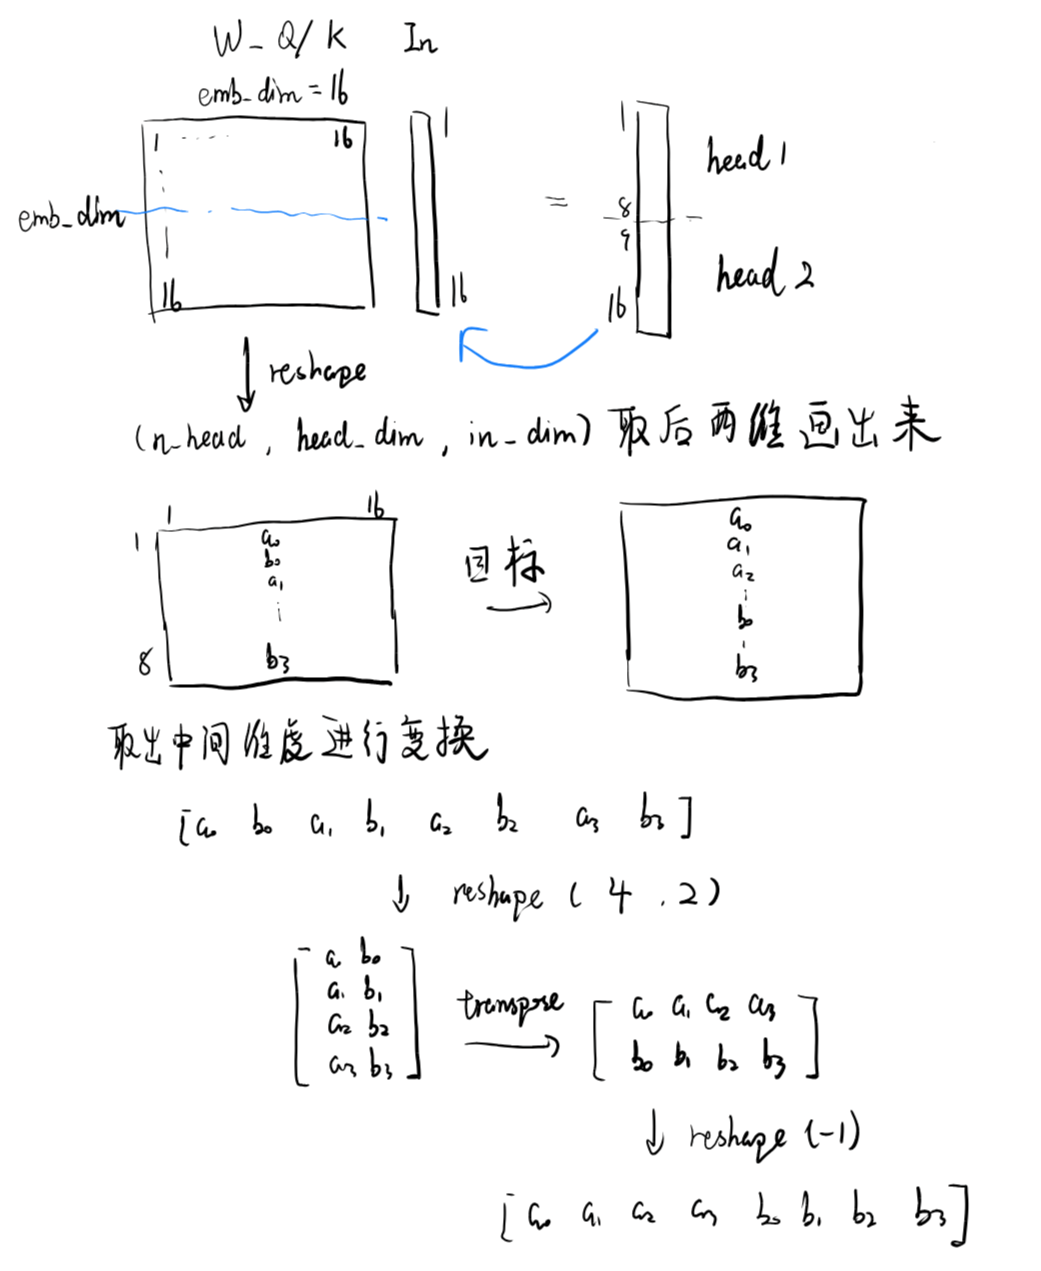

**步骤 1：`w.view(n_heads, head_dim // 2, 2, in_dim)`**  
将 `out_dim` 维度重塑为 `(n_heads, head_dim//2, 2)`。  
对于 `n_heads=2, head_dim=8`，形状变为 `(2, 4, 2, in_dim)`。  
第 1 维是头索引，第 2 维是“对索引”（共 4 对），第 3 维是“对内的位置”（0 或 1）。  
此时数据在内存中仍然是连续的，但被重新解释为：  
头 0：`[[a0, b0], [a1, b1], [a2, b2], [a3, b3]]`  
头 1：`[[a0', b0'], [a1', b1'], ...]`

**步骤 2：`.transpose(1, 2)`**  
交换第 1 维（对索引）和第 2 维（对内的位置）。  
形状变为 `(n_heads, 2, head_dim//2, in_dim)`，即 `(2, 2, 4, in_dim)`。  
此时对于每个头，第 1 维大小为 2，表示“对内的位置”（0 对应所有对的第一个元素，1 对应所有对的第二个元素）；第 2 维大小为 4，表示“对索引”。  
头 0 的数据变为：  
位置 0：`[a0, a1, a2, a3]`  
位置 1：`[b0, b1, b2, b3]`

**步骤 3：`.reshape(out_dim, in_dim)`**  
将前三个维度合并回 `out_dim`。  
合并时按行优先顺序：先取位置 0 的所有对索引，再取位置 1 的所有对索引。  
因此头 0 的元素顺序变为：  
`[a0, a1, a2, a3, b0, b1, b2, b3]`  
这正是**切片排列**。

所以，`permute` 完成了 **交错排列 → 切片排列** 的转换。

**3. 赋值给模型**

```python
q_raw = params[f"layers.{l}.attention.wq.weight"]
model.trf_blocks[l].att.W_query.weight = assign(
    model.trf_blocks[l].att.W_query.weight,
    permute(q_raw, cfg["n_heads"], cfg["emb_dim"], cfg["emb_dim"])
)
```
- `q_raw` 形状 `(d_out, d_in)`，其中 `d_out = n_heads * head_dim = cfg["emb_dim"]`，`d_in = cfg["emb_dim"]`。
- 经过 `permute` 后，形状不变，仍为 `(d_out, d_in)`，但 `out_dim` 维度上的元素顺序从交错变为切片。
- 然后通过 `assign` 复制到模型的 `W_query.weight` 中（形状相同，直接 `copy_`）。

K 权重的处理完全相同。

### 使用指令微调的模型

前面我们只加载了预训练模型。Llama2 还提供了指令微调模型（类似 ChatGPT），可以自行通过下面的代码加载并使用。这里 notebook 就默认不运行了，需要可以自行打开。

In [ ]:
if False:
    del model  # 释放上一次加载的模型

    weights_file = hf_hub_download(
    repo_id="meta-llama/Llama-2-7b-chat",
    filename="consolidated.00.pth",
    local_dir="Llama-2-7b-chat"
    )

    weights = torch.load(weights_file, weights_only=True)
    model = Llama2Model(LLAMA2_CONFIG_7B)
    load_weights_into_llama(model, LLAMA2_CONFIG_7B, weights)
    model.to(device);

    torch.manual_seed(123)

    token_ids = generate(
        model=model,
        idx=text_to_token_ids("What do llamas eat?", tokenizer).to(device),
        max_new_tokens=25,
        context_size=LLAMA2_CONFIG_7B["context_length"],
        top_k=1,
        temperature=0.
    )

    print("Output text:\n", token_ids_to_text(token_ids, tokenizer))